# 01. Exploratory Data Analysis (EDA)

**Goal of this notebook:** understand *who* leaves the operator and *why*, before building any model.
Every hypothesis we find here later becomes a feature in `src/churn/features.py`.

**Dataset:** [IBM Telco Customer Churn](https://github.com/IBM/telco-customer-churn-on-icp4d): 7,043 customers
of a fictional telecom operator, 21 columns covering demographics, subscribed services, contract, billing,
and the target `Churn` (whether the customer left within the last month).

Plan:
1. First look at the data and its quality
2. The target and class imbalance
3. Numeric features: tenure, charges
4. Categorical features: contract, payment, services
5. Interactions and correlations
6. Conclusions → features for the model

In [1]:
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

from churn.data import clean, download_data, load_raw

sns.set_theme(style="whitegrid", palette="deep")
pd.set_option("display.max_columns", 30)

raw = load_raw(download_data())
raw.head()

,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


## 1. First look at the data

We check column types and missing values. A classic trap in this dataset: `TotalCharges` should be a number,
but pandas reads it as `object` (a string).

In [2]:
raw.info()

<class 'pandas.DataFrame'>
RangeIndex: 7043 entries, 0 to 7042
Data columns (total 21 columns):
 #   Column            Non-Null Count  Dtype  
---  ------            --------------  -----  
 0   customerID        7043 non-null   str    
 1   gender            7043 non-null   str    
 2   SeniorCitizen     7043 non-null   int64  
 3   Partner           7043 non-null   str    
 4   Dependents        7043 non-null   str    
 5   tenure            7043 non-null   int64  
 6   PhoneService      7043 non-null   str    
 7   MultipleLines     7043 non-null   str    
 8   InternetService   7043 non-null   str    
 9   OnlineSecurity    7043 non-null   str    
 10  OnlineBackup      7043 non-null   str    
 11  DeviceProtection  7043 non-null   str    
 12  TechSupport       7043 non-null   str    
 13  StreamingTV       7043 non-null   str    
 14  StreamingMovies   7043 non-null   str    
 15  Contract          7043 non-null   str    
 16  PaperlessBilling  7043 non-null   str    
 17  Paymen

In [3]:
blank = raw["TotalCharges"].str.strip() == ""
print(f"Blank TotalCharges: {blank.sum()}")
raw.loc[blank, ["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Churn"]]

Blank TotalCharges: 11


,customerID,tenure,MonthlyCharges,TotalCharges,Churn
488,4472-LVYGI,0,52.55,,No
753,3115-CZMZD,0,20.25,,No
936,5709-LVOEQ,0,80.85,,No
1082,4367-NUYAO,0,25.75,,No
1340,1371-DWPAZ,0,56.05,,No
3331,7644-OMVMY,0,19.85,,No
3826,3213-VVOLG,0,25.35,,No
4380,2520-SGTTA,0,20.00,,No
5218,2923-ARZLG,0,19.70,,No
6670,4075-WKNIU,0,73.35,,No


**What we see:** 11 customers have `TotalCharges = " "`, and all of them have `tenure = 0`. These are new customers
who have not received a single bill yet. So this is not a "missing value", it is a zero. Dropping the rows or
filling them with the median would be a mistake: `clean()` sets them to 0 and converts the target to 0/1.

> 💡 Before filling missing values, find out **why** they are missing. The cause often tells you the right value.

In [4]:
df = clean(raw)
print("Duplicate customerIDs:", df["customerID"].duplicated().sum())
df.describe().T

Duplicate customerIDs: 0


,count,mean,std,min,25%,50%,75%,max
SeniorCitizen,7043.0,0.162147,0.368612,0.00,0.00,0.00,0.00,1.00
tenure,7043.0,32.371149,24.559481,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,7043.0,64.761692,30.090047,18.25,35.50,70.35,89.85,118.75
TotalCharges,7043.0,2279.734304,2266.794470,0.00,398.55,1394.55,3786.60,8684.80
Churn,7043.0,0.265370,0.441561,0.00,0.00,0.00,1.00,1.00


## 2. The target

**26.5%** of customers churn. The classes are imbalanced (roughly 1:3), which affects three things:
* **Accuracy is misleading.** A "nobody leaves" model has 73.5% accuracy and zero value.
  So we look at ROC-AUC, PR-AUC, precision and recall.
* **The split must be stratified**, so train and test have the same churn rate.
* **Models should be "reminded" about the rarer class** via `class_weight="balanced"` or `scale_pos_weight`.

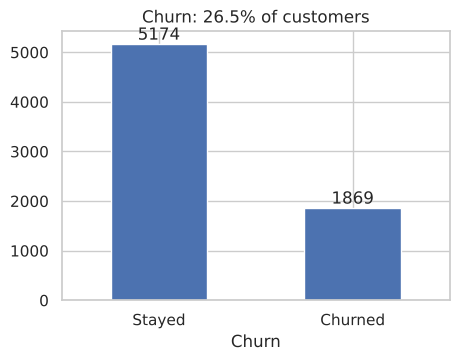

In [5]:
ax = df["Churn"].map({0: "Stayed", 1: "Churned"}).value_counts().plot.bar(rot=0, figsize=(5, 3.5))
ax.bar_label(ax.containers[0])
ax.set_title(f"Churn: {df['Churn'].mean():.1%} of customers")
plt.show()

## 3. Numeric features

There are three numeric columns: `tenure` (months with the operator), `MonthlyCharges` and `TotalCharges`.
We compare their distributions for customers who left and those who stayed.

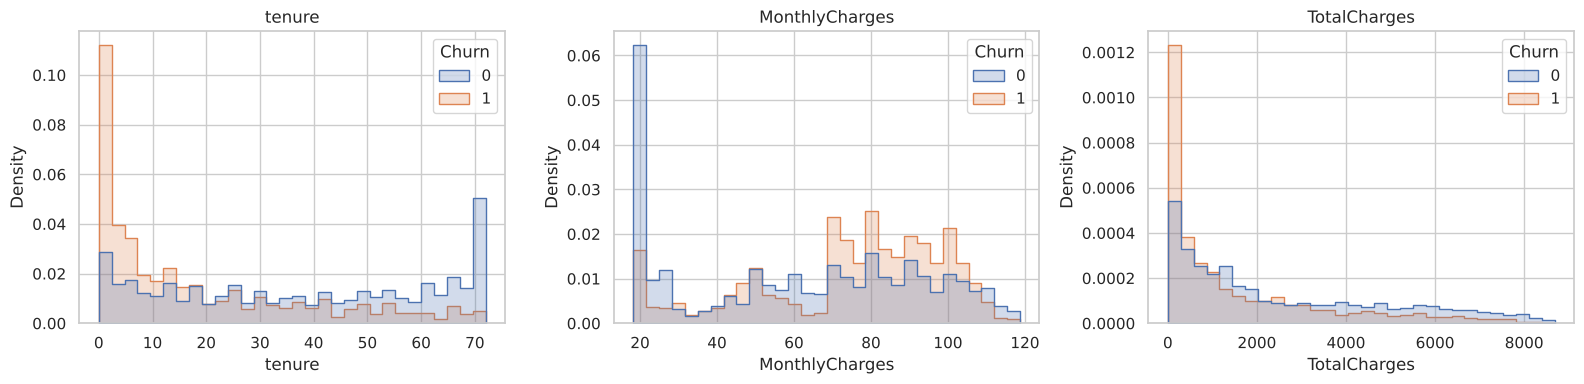

In [6]:
fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, col in zip(axes, ["tenure", "MonthlyCharges", "TotalCharges"], strict=True):
    sns.histplot(data=df, x=col, hue="Churn", stat="density", common_norm=False,
                 element="step", bins=30, ax=ax)
    ax.set_title(col)
plt.tight_layout()
plt.show()

**Takeaways:**
* **`tenure` is the strongest numeric signal.** Customers who leave do so in their first months.
  After 2 years churn is rare. Hence the `is_new_customer` feature (tenure ≤ 6).
* **`MonthlyCharges`:** churners include more customers with high bills ($70–110).
* **`TotalCharges`** ≈ `tenure × MonthlyCharges`, so it mostly duplicates information (see correlations below).

Let's look at churn by tenure in more detail.

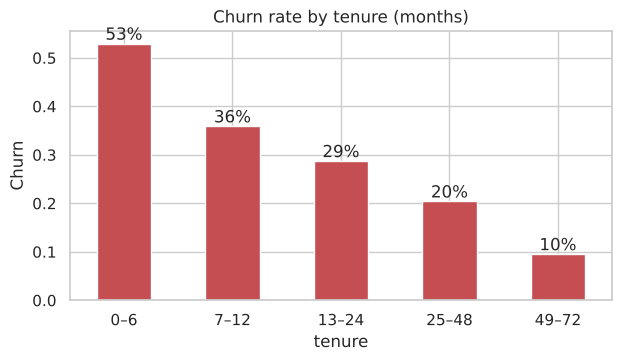

,mean,size
tenure,,
0–6,0.529372,1481
7–12,0.358865,705
13–24,0.287109,1024
25–48,0.203890,1594
49–72,0.095132,2239


In [7]:
tenure_bins = pd.cut(df["tenure"], bins=[-1, 6, 12, 24, 48, 72],
                     labels=["0–6", "7–12", "13–24", "25–48", "49–72"])
rate = df.groupby(tenure_bins, observed=True)["Churn"].agg(["mean", "size"])
ax = rate["mean"].plot.bar(rot=0, figsize=(7, 3.5), color="C3")
ax.bar_label(ax.containers[0], labels=[f"{v:.0%}" for v in rate["mean"]])
ax.set(title="Churn rate by tenure (months)", ylabel="Churn", xlabel="tenure")
plt.show()
rate

Newcomers (0–6 months) leave in **~53%** of cases, veterans (4+ years) in only **~9.5%**.
For the business this means the first six months are the critical window for retention programs.

## 4. Categorical features

For every category we compute the churn rate. The dashed line is the overall average (26.5%).

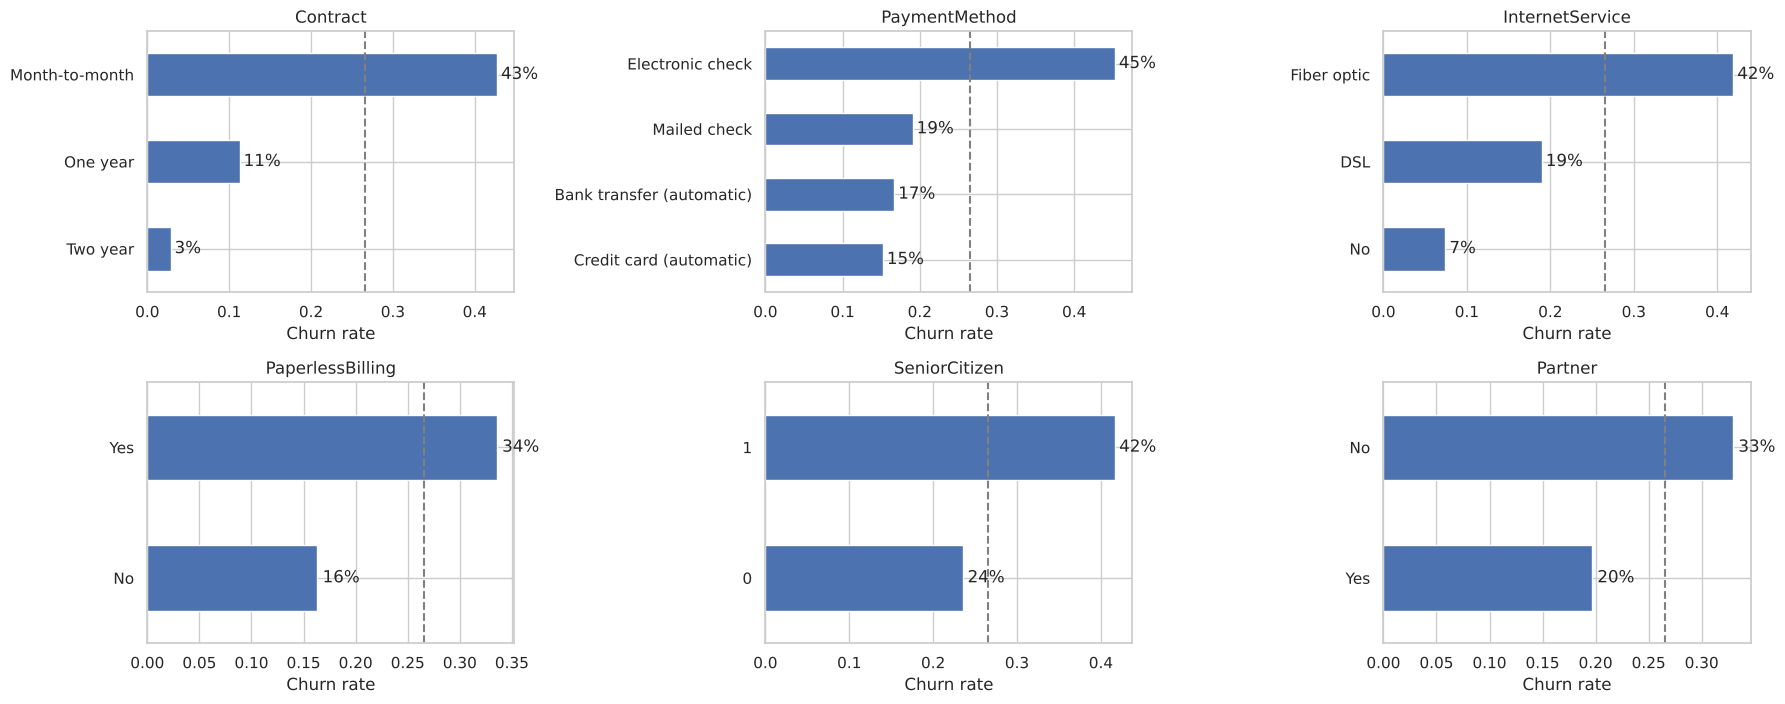

In [8]:
def churn_rate_plot(cols, ncols=3):
    nrows = int(np.ceil(len(cols) / ncols))
    fig, axes = plt.subplots(nrows, ncols, figsize=(6 * ncols, 3.6 * nrows))
    for ax, col in zip(np.ravel(axes), cols, strict=False):
        r = df.groupby(col)["Churn"].mean().sort_values()
        r.plot.barh(ax=ax, color="C0")
        ax.axvline(df["Churn"].mean(), ls="--", color="grey")
        ax.set(title=col, xlabel="Churn rate", ylabel="")
        for i, v in enumerate(r):
            ax.text(v + 0.005, i, f"{v:.0%}", va="center")
    for ax in np.ravel(axes)[len(cols):]:
        ax.set_visible(False)
    plt.tight_layout()
    plt.show()

churn_rate_plot(["Contract", "PaymentMethod", "InternetService",
                 "PaperlessBilling", "SeniorCitizen", "Partner"])

**The strongest signals:**
* **Contract.** Month-to-month gives ~43% churn, a two-year contract only ~3%. Nothing holds the customer,
  so they leave. Feature `is_month_to_month`.
* **Electronic check** gives ~45% churn versus ~15–17% for automatic payments. Autopay creates inertia,
  while paying manually every month is a monthly reminder of the cost. Feature `is_electronic_check`.
* **Fiber optic** gives ~42%, even though it is the "better" internet. A likely cause is a high price or quality issues.
  Feature `has_fiber`.
* Seniors, customers without a partner and those with paperless billing also leave more often.

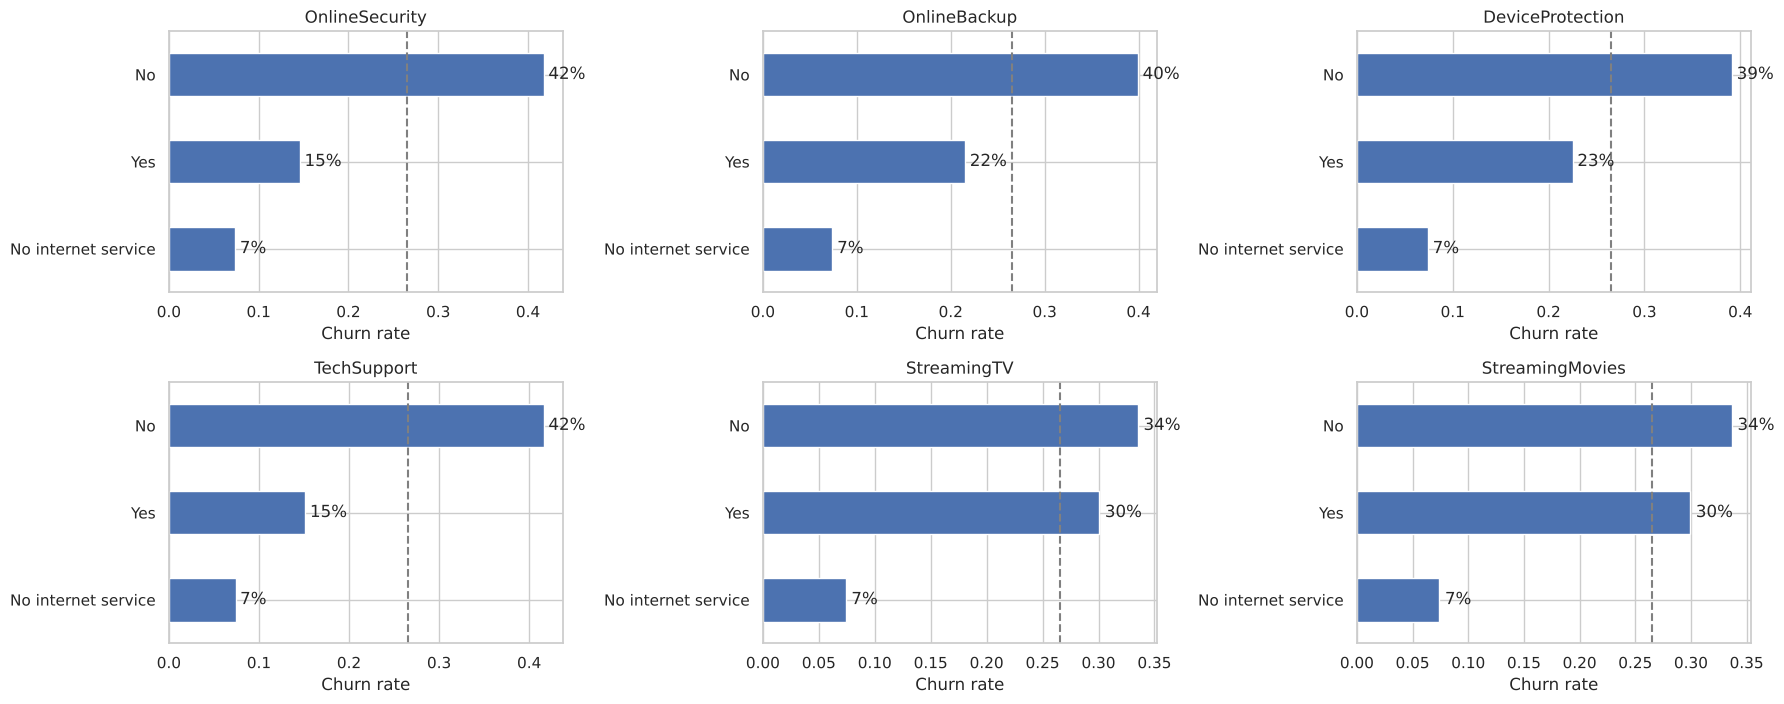

In [9]:
churn_rate_plot(["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"])

**Add-on services:**
* Customers **without OnlineSecurity** or **without TechSupport** leave almost three times as often (~42% vs ~15%).
  With neither of the two, churn is ~49% vs ~17%. Hence the `no_protection` feature.
* Streaming barely affects churn.
* Every service adds a "tie" to the operator. Let's test the hypothesis that more services means less churn.

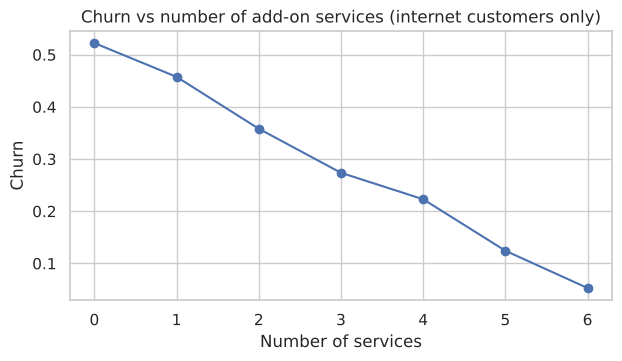

,mean,size
num_addon_services,,
0,0.522367,693
1,0.457557,966
2,0.358180,1033
3,0.273703,1118
4,0.223005,852
5,0.124343,571
6,0.052817,284


In [10]:
addons = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
          "TechSupport", "StreamingTV", "StreamingMovies"]
df["num_addon_services"] = (df[addons] == "Yes").sum(axis=1)
internet = df[df["InternetService"] != "No"]
r = internet.groupby("num_addon_services")["Churn"].agg(["mean", "size"])
ax = r["mean"].plot(marker="o", figsize=(7, 3.5))
ax.set(title="Churn vs number of add-on services (internet customers only)",
       xlabel="Number of services", ylabel="Churn")
plt.show()
r

The hypothesis holds: with 0–1 services churn is ~46–52%, with 5–6 only ~5–12%, and the decline is monotonic.
`num_addon_services` becomes one of our features.

## 5. Interactions and correlations

Contract and tenure are strongly linked: loyal customers sign long contracts. Let's look at them together.

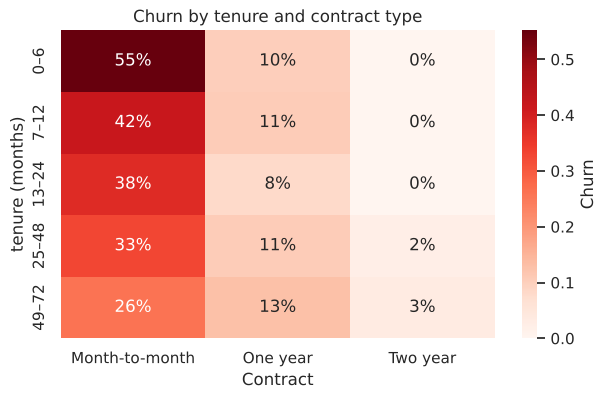

In [11]:
pivot = df.pivot_table(index=tenure_bins, columns="Contract", values="Churn", aggfunc="mean",
                       observed=True)
plt.figure(figsize=(7, 4))
sns.heatmap(pivot, annot=True, fmt=".0%", cmap="Reds", cbar_kws={"label": "Churn"})
plt.title("Churn by tenure and contract type")
plt.ylabel("tenure (months)")
plt.show()

Even among newcomers, a one- or two-year contract cuts churn sharply. The effects are partly independent,
so the model benefits from seeing both features. Trees (XGBoost, LightGBM) find such interactions automatically.

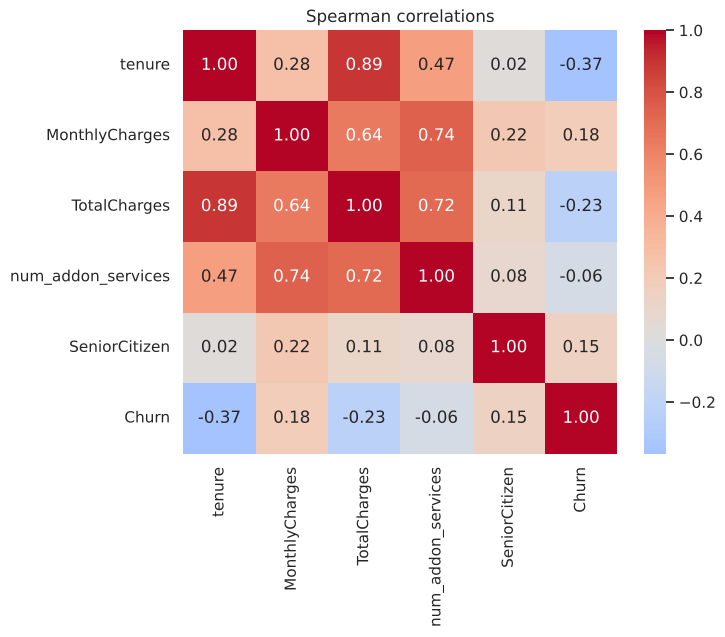

In [12]:
cols = ["tenure", "MonthlyCharges", "TotalCharges", "num_addon_services", "SeniorCitizen", "Churn"]
plt.figure(figsize=(7, 5.5))
sns.heatmap(df[cols].corr(method="spearman"), annot=True, fmt=".2f", cmap="coolwarm", center=0)
plt.title("Spearman correlations")
plt.show()

* `TotalCharges` is very strongly correlated with `tenure` (ρ ≈ 0.89). Multicollinearity does not bother trees,
  but it makes logistic regression coefficients less stable. Regularization (`C=0.5`) softens this.
* `tenure` has the strongest (negative) correlation with churn.

### The `charge_delta` feature
If the current `MonthlyCharges` is higher than the average actual payment (`TotalCharges / tenure`),
the customer's bill has grown; if lower, it has dropped. Hypothesis: a price change triggers churn.

In [13]:
safe = df["tenure"].replace(0, np.nan)
df["charge_delta"] = df["MonthlyCharges"] - (df["TotalCharges"] / safe).fillna(df["MonthlyCharges"])
q = pd.qcut(df["charge_delta"], 5, duplicates="drop")
df.groupby(q, observed=True)["Churn"].mean().to_frame("Churn")

,Churn
charge_delta,
"(-18.901, -1.523]",0.308020
"(-1.523, -0.299]",0.163352
"(-0.299, 0.285]",0.367637
"(0.285, 1.535]",0.169744
"(1.535, 19.125]",0.317956


The result is **not monotonic**, which is an honest EDA lesson: the hypothesis was only partly confirmed.
Churn is higher at both ends (the bill grew *or* dropped noticeably) and in the middle bucket,
which holds customers with `tenure` ≤ 1 whose delta is exactly 0 by construction.
A linear model will not capture such a U-shaped relationship, but trees will. We keep the feature,
and SHAP in the next notebook will show whether it is useful.

## 6. Conclusions

| EDA observation | Feature in `features.py` |
|---|---|
| Month-to-month contract gives ~43% churn | `is_month_to_month` |
| Risk is highest in the first 6 months | `is_new_customer`, `tenure_years` |
| Electronic check gives ~45% churn | `is_electronic_check` |
| Fiber optic, despite the quality, gives ~42% | `has_fiber` |
| Without protection/support churn is almost 3× higher | `no_protection` |
| More services means less churn | `num_addon_services` |
| Change in the bill (U-shaped relationship) | `charge_delta`, `avg_monthly_spend` |

**Data quality:** 11 blank `TotalCharges` set to 0 (new customers), no duplicates.

**Modeling decisions:**
* ROC-AUC and PR-AUC instead of accuracy;
* stratified split and cross-validation;
* class weights for the imbalance;
* the classification threshold is chosen by business value, not 0.5.

Next: [`02_modeling_and_explainability.ipynb`](02_modeling_and_explainability.ipynb).